# Phase 8 · 트랜스포머 블록 — 조각을 하나로 🧱

웹 챕터 **"트랜스포머 블록"** 과 짝을 이루는 실습입니다.
웹에서 잔차·정규화 토글을 봤다면, 여기서는 **깊게 쌓을 때 신호 크기**를 직접 계산하고
**블록 한 개의 순전파**도 코드로 돌려 봅니다.

준비물: `pip install -r requirements.txt`

> 🤖 **AI 튜터** — 아래 셀을 실행하면 웹앱처럼 화면 오른쪽 아래에 🤖 버튼이 생깁니다.
> 버튼을 누르면 채팅창이 열리고, 어디를 스크롤해도 그 자리에 떠 있어요. 막히면 언제든 질문하세요.
> (로컬 Ollama 필요 — 꺼져 있으면 켜는 방법이 안내되고, 튜터 없이도 학습에는 지장 없습니다.)

In [ ]:
# 🤖 AI 튜터 — 실행하면 오른쪽 아래에 🤖 버튼이 떠요
from tutor import chat

chat('ch8')

## 1. 왜 잔차연결·층정규화가 필요한가

층을 여러 번 지날 때 신호 크기가 어떻게 변하는지 봅시다. (웹 실험실과 같은 규칙)
- 둘 다 없음 → 소멸,  잔차만 → 폭발,  층정규화 있음 → 안정

In [1]:
import numpy as np

SUB = 0.5  # 서브층이 신호를 줄이는 정도(예시)

def stack(layers, residual, norm):
    mags = [1.0]; m = 1.0
    for _ in range(layers):
        sub = SUB * m
        m = m + sub if residual else sub   # 잔차연결
        if norm: m = 1.0                    # 층정규화(크기 리셋)
        mags.append(m)
    return mags

L = 10
print('둘 다 없음  :', round(stack(L, False, False)[-1], 3), '→ 소멸')
print('잔차만     :', round(stack(L, True,  False)[-1], 1), '→ 폭발')
print('잔차+정규화:', round(stack(L, True,  True )[-1], 3), '→ 안정')

둘 다 없음  : 0.001 → 소멸
잔차만     : 57.7 → 폭발
잔차+정규화: 1.0 → 안정


## 2. 신호 크기 그래프

세 경우를 겹쳐 그리면 차이가 한눈에 보입니다.

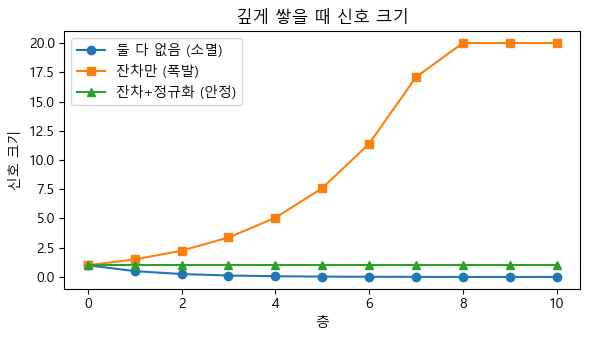

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

L = 10
plt.figure(figsize=(6, 3.5))
plt.plot(stack(L, False, False), 'o-', label='둘 다 없음 (소멸)')
plt.plot([min(v, 20) for v in stack(L, True, False)], 's-', label='잔차만 (폭발)')
plt.plot(stack(L, True, True), '^-', label='잔차+정규화 (안정)')
plt.xlabel('층'); plt.ylabel('신호 크기'); plt.legend(); plt.title('깊게 쌓을 때 신호 크기')
plt.tight_layout(); plt.show()

## 3. 블록 한 개의 순전파

블록 = [어텐션 → Add&Norm → 피드포워드 → Add&Norm]. 각 서브층을 **잔차 + 정규화**로 감쌉니다.
여기선 어텐션·FFN 을 간단한 함수로 대체해 구조만 봅니다.

In [3]:
def layer_norm(x, eps=1e-5):
    mu = x.mean(); sd = x.std()
    return (x - mu) / (sd + eps)   # 평균 0, 표준편차 1 로

def sublayer_attention(x):
    return 0.5 * x           # (진짜 멀티헤드 어텐션 자리)

def sublayer_ffn(x):
    return np.tanh(x) * 0.8  # (진짜 FFN 자리: 비선형 변환)

def block(x):
    x = layer_norm(x + sublayer_attention(x))   # Add & Norm
    x = layer_norm(x + sublayer_ffn(x))         # Add & Norm
    return x

x = np.array([2.0, 1.0, -1.0, 0.5])
print('입력      :', np.round(x, 2))
print('블록 출력 :', np.round(block(x), 2))

입력      : [ 2.   1.  -1.   0.5]
블록 출력 : [ 1.27  0.38 -1.49 -0.16]


## 4. 블록 여러 개 쌓기

같은 블록을 반복 통과시켜도, 잔차+정규화 덕분에 값이 안정적으로 유지됩니다.

In [4]:
x = np.array([2.0, 1.0, -1.0, 0.5])
for i in range(1, 7):
    x = block(x)
    print(f'{i}번째 블록 후 크기: {np.linalg.norm(x):.3f}')   # 폭발/소멸 없이 안정

1번째 블록 후 크기: 2.000
2번째 블록 후 크기: 2.000
3번째 블록 후 크기: 2.000
4번째 블록 후 크기: 2.000
5번째 블록 후 크기: 2.000
6번째 블록 후 크기: 2.000


## 5. 직접 해보기 ✏️

잔차연결: 입력 `(2, 1)` 에 서브층 출력 `(0.5, 0.3)` 을 더하면? (웹 StepQuiz 와 같은 문제)

In [5]:
inp = np.array([2.0, 1.0])
f   = np.array([0.5, 0.3])
outp = inp + f      # 잔차연결: 입력 + f(입력)
print('출력:', outp)

assert np.allclose(outp, [2.5, 1.3]), '입력에 서브층 출력을 성분끼리 더하세요!'
print('✅ (2.5, 1.3) — 입력이 지름길로 그대로 더해졌습니다.')

출력: [2.5 1.3]
✅ (2.5, 1.3) — 입력이 지름길로 그대로 더해졌습니다.


---
**어텐션 + 잔차 + 정규화 + FFN = 트랜스포머 블록**, 이걸 여러 층 쌓으면 본체 완성! 🧱🧱🧱
블록을 다 통과한 벡터는 다음 챕터(ch9 출력층)에서 **다음 단어의 확률**이 됩니다. 🎲